# Flood Timing Prediction — Validation Notebook

Goal: evaluate candidate methods for predicting **when** each gauge will
(1) **start flooding** (cross its flood-alert / road stage on the rise),
(2) **crest**, and (3) **stop flooding** (fall back below the threshold) —
using **nearby upriver gauges** rather than (only) the NWRFC forecast.

This complements `svpa-forecast-regression.ipynb`, which predicts *how high*
each SVPA gauge will get (and the probability of flooding) from the NWRFC-forecast
USGS gauges. Timing has two phases:

1. **Forecast-based** (days out): NWRFC's 6-hour forecast timestep means ±3 h
   resolution at best. Not evaluated here.
2. **Upriver-based** (during the event): the subject of this notebook.

Each section below validates one method option against the historical record and
ends with a verdict. Jump to **Conclusions** at the bottom for the summary and a
recommended architecture.

| Section | Question |
|---|---|
| 1 | Which *crest-time definition* tames flat crests and reduces gauge-to-gauge lag variance? |
| 2 | Does travel time depend on flood magnitude, and in which direction? |
| 3 | Can an upstream **trigger level** predict *start-of-flooding* time, and with what warning? |
| 4 | How good is simple **rate-of-rise extrapolation** near the crossing? |
| 5 | How predictable is *end-of-flooding* (trigger fall-below vs recession curve)? |
| 6 | How early can we *confirm a gauge has crested*, and does upstream-crest status help? |
| 7 | Do closer upstream **SVPA gauges** tighten the prediction as the crest approaches? |
| 8 | What does the literature / other operational systems do? |

Assumes the working directory is `notebooks/` (paths use `../`), matching the
other notebooks. Requires `data/` populated via `fetch-gauge-data.py` for all
stations in `locations.json` (plus Duvall), i.e. USGS water years 1988–2026 and
SVPA 2020–2026.

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
from scipy.signal import find_peaks

# Emit a static PNG alongside the interactive view so charts render on GitHub.
try:
    import kaleido  # noqa: F401
    pio.renderers.default = "plotly_mimetype+png"
except ImportError:
    pio.renderers.default = "plotly_mimetype"

warnings.filterwarnings("ignore", message=".*Pandas4Warning.*")
pd.set_option("display.width", 220)

ROOT = Path("..")

# Categorical palette (colorblind-safe ordering; see dataviz notes)
PAL = ["#2a78d6", "#1baf7a", "#eda100", "#008300", "#4a3aa7", "#e34948", "#e87ba4", "#eb6834"]
GRAY = "#9a9891"

FALLS, CARN, DUV = "12144500", "12149000", "12150400"

with open(ROOT / "locations.json") as f:
    locations = json.load(f)["locations"]
NAME = {l["id"]: l["name"] for l in locations}
RM = {l["id"]: l.get("riverMile") for l in locations}

with open(ROOT / "data_files" / "floodzilla-predictions.json") as f:
    PRED = json.load(f)
P50 = {g["gaugeId"]: g["floodProbability"]["p50"] for g in PRED["gauges"]}
PRED_USGS = {g["gaugeId"]: g["predictor"]["usgsSiteId"] for g in PRED["gauges"]}

# Flood-alert ("yellow") stages, from the manually cleaned historic-crest table.
_hc = pd.read_csv(ROOT / "data_files" / "historic_crests_cleaned.csv")
_fzid = {"USGS-22": CARN, "USGS-38": FALLS, "USGS-9": DUV}
YELLOW = {_fzid.get(k, k): v
          for k, v in _hc.groupby("gaugeId")["yellowStage"].first().dropna().items()}

# Physically-upstream USGS gauge used as the *timing* predictor for each station.
# NOTE: this differs from the *height* predictor in floodzilla-predictions.json —
# SVPA-25/26/29 (RM 25-29) regress on Carnation (RM 22) for height, but Carnation
# is DOWNSTREAM of them, so it cannot lead them in time. For timing they must key
# off Falls.
TIMING_PRED = {
    "SVPA-37": FALLS, "SVPA-36": FALLS, "SVPA-34": FALLS, "SVPA-33": FALLS,
    "SVPA-29": FALLS, "SVPA-26": FALLS, "SVPA-25": FALLS,
    CARN: FALLS,
    "SVPA-19": CARN, "SVPA-17": CARN, "SVPA-15": CARN, "SVPA-15B": CARN,
    "SVPA-12": CARN, DUV: CARN,
}
SVPA_GAUGES = [g for g in TIMING_PRED if g.startswith("SVPA")]
print(f"{len(SVPA_GAUGES)} SVPA gauges; yellow stages for {len(YELLOW)} stations")

12 SVPA gauges; yellow stages for 14 stations


In [2]:
def load_stage(source: str, gid: str) -> pd.Series:
    """All years of stage for one gauge on a 15-min grid (UTC, tz-naive).

    Cleaning: drop dup timestamps, kill single-point spikes (>2 ft against both
    neighbors), average onto a 15-min grid, interpolate gaps up to 2 h so
    threshold-crossing times are well defined.
    """
    files = sorted((ROOT / "data" / source.lower() / gid).glob("*.parquet"))
    if not files:
        raise FileNotFoundError(f"data/{source.lower()}/{gid} — run fetch-gauge-data.py")
    s = pd.concat([pd.read_parquet(f)[["stage"]] for f in files])["stage"].astype(float)
    s.index = pd.to_datetime(s.index, utc=True).tz_localize(None)
    s = s[~s.index.duplicated()].sort_index().dropna()
    d1, d2 = s.diff(), s.diff(-1)
    spike = (d1.abs() > 2) & (d2.abs() > 2) & (np.sign(d1) == np.sign(d2))
    s = s[~spike]
    return s.resample("15min").mean().interpolate(limit=8)

SERIES = {}
for src, gid in ([("usgs", FALLS), ("usgs", CARN), ("usgs", DUV)]
                 + [("svpa", g) for g in SVPA_GAUGES]):
    SERIES[gid] = load_stage(src, gid)
    ix = SERIES[gid].dropna().index
    print(f"{gid:9s} {NAME[gid]:16s} {ix.min().date()} -> {ix.max().date()}")

12144500  Falls            2007-10-01 -> 2026-06-06
12149000  Carnation        2007-10-01 -> 2026-06-06


12150400  Duvall           2007-12-04 -> 2026-06-06
SVPA-37   Sno Falls Golf   2019-11-07 -> 2026-05-11
SVPA-36   Neal Road        2021-09-15 -> 2026-05-11
SVPA-34   The T            2019-10-21 -> 2026-05-05


SVPA-33   Keller Dairy     2019-10-21 -> 2026-05-11
SVPA-29   Jubilee Farm     2021-02-22 -> 2026-05-11
SVPA-26   Blue Heron Golf  2019-10-21 -> 2026-05-11
SVPA-25   Tolt Hill Road   2020-10-12 -> 2026-06-07
SVPA-19   Stuart Landing   2023-11-27 -> 2026-05-11


SVPA-17   Goose & Gander Farm 2019-10-02 -> 2026-04-30
SVPA-15   124th East       2019-10-22 -> 2026-06-07
SVPA-15B  124th West       2020-09-16 -> 2026-05-08
SVPA-12   Wild Canary Farm 2019-10-16 -> 2026-04-28


In [3]:
# Flood-event catalog: windows around detected Carnation crests.
def load_events(min_stage: float, since=None) -> pd.DataFrame:
    c = pd.read_csv(ROOT / "crests" / "usgs" / CARN / f"usgs-{CARN}-crests.csv", sep="\t")
    c["utc"] = pd.to_datetime(c["utc"])
    ev = c[c["stage"] >= min_stage]
    if since:
        ev = ev[ev["utc"] >= since]
    return ev.reset_index(drop=True)

EVENTS_ALL = load_events(51.0)                       # all-time, Carnation >= flood stage
EVENTS_SVPA = load_events(48.0, since="2019-10-01")  # SVPA era; lower bar => more threshold crossings
PRE = POST = pd.Timedelta("2D")

def window(gid: str, t: pd.Timestamp, post: pd.Timedelta = None) -> pd.Series | None:
    """Event window for one gauge; None if sparse or the peak is truncated at an edge."""
    w = SERIES[gid].loc[t - PRE: t + (post or POST)].dropna()
    if len(w) < 100:
        return None
    if w.idxmax() in (w.index[0], w.index[-1]):
        return None
    return w

print(f"{len(EVENTS_ALL)} events all-time (Carnation >= 51 ft), "
      f"{len(EVENTS_SVPA)} since 2019-10 (>= 48 ft)")
print("Note: consecutive crests < 2 days apart produce overlapping windows; "
      "per-gauge results are deduped on crossing/crest time below.")

105 events all-time (Carnation >= 51 ft), 124 since 2019-10 (>= 48 ft)
Note: consecutive crests < 2 days apart produce overlapping windows; per-gauge results are deduped on crossing/crest time below.


In [4]:
# ---- candidate crest-time definitions + threshold-crossing helper ----

def cross_time(w: pd.Series, level: float, rising: bool, t_ref=None):
    """Interpolated time the series crosses `level`.
    rising=True : last upward crossing before the peak (default t_ref).
    rising=False: first downward crossing after the peak."""
    if w.empty or w.max() < level:
        return None
    t_ref = t_ref if t_ref is not None else w.idxmax()
    seg = w.loc[:t_ref] if rising else w.loc[t_ref:]
    va = seg.values >= level
    if rising:
        idx = np.where(~va[:-1] & va[1:])[0]
        if len(idx) == 0:
            return seg.index[0] if va.all() else None
        i = idx[-1]
    else:
        idx = np.where(va[:-1] & ~va[1:])[0]
        if len(idx) == 0:
            return None
        i = idx[0]
    x0, x1 = seg.values[i], seg.values[i + 1]
    t0, t1 = seg.index[i], seg.index[i + 1]
    return t1 if x1 == x0 else t0 + (t1 - t0) * (level - x0) / (x1 - x0)


def crest_times(w: pd.Series, offsets=(0.2, 0.5, 1.0)) -> dict:
    """Candidate crest-time estimates for one event window.

    peak        argmax (the current definition in calc-crests.py)
    parab       vertex of a quadratic fit to points within 0.5 ft of the peak
    rise-d      last upward crossing of (peak - d) on the rising limb
    mid-d       midpoint of the rising and falling crossings of (peak - d)
    centroid-d  stage-weighted time centroid of the region above (peak - d)
    plateau_h   half-width (hours) of the contiguous span within 0.15 ft of the
                peak — an honest per-event uncertainty on the peak time itself
    """
    out = {}
    if w.empty:
        return out
    peak, t_peak = w.max(), w.idxmax()
    out["peak"], out["peak_stage"] = t_peak, peak
    tr15 = cross_time(w, peak - 0.15, rising=True)
    tf15 = cross_time(w, peak - 0.15, rising=False)
    if tr15 is not None and tf15 is not None:
        out["plateau_h"] = (tf15 - tr15).total_seconds() / 7200.0
    near = w[w >= peak - 0.5]
    if len(near) >= 5:
        x = np.asarray((near.index - t_peak).total_seconds()) / 3600.0
        c = np.polyfit(x, near.values, 2)
        if c[0] < 0 and abs(-c[1] / (2 * c[0])) < 24:
            out["parab"] = t_peak + pd.Timedelta(hours=-c[1] / (2 * c[0]))
    for d in offsets:
        lvl = peak - d
        tr = cross_time(w, lvl, rising=True)
        tf = cross_time(w, lvl, rising=False)
        if tr is not None:
            out[f"rise-{d}"] = tr
            if tf is not None:
                out[f"mid-{d}"] = tr + (tf - tr) / 2
        above = w[w >= lvl]
        if len(above) >= 2 and (above.values - lvl).sum() > 0:
            wts = above.values - lvl
            secs = np.asarray((above.index - t_peak).total_seconds())
            out[f"centroid-{d}"] = t_peak + pd.Timedelta(seconds=float((secs * wts).sum() / wts.sum()))
    return out


def xcorr_lag(wu: pd.Series, wd: pd.Series, lo_h=-12, hi_h=30):
    """Lag (h) maximizing correlation of the two *derivative* series — a whole-
    hydrograph travel-time estimate that ignores the crest entirely."""
    g = pd.date_range(min(wu.index[0], wd.index[0]), max(wu.index[-1], wd.index[-1]), freq="15min")
    du = wu.reindex(g).interpolate(limit=8).diff().rolling(4).mean()
    dd = wd.reindex(g).interpolate(limit=8).diff().rolling(4).mean()
    best, best_r = None, -2.0
    for k in range(int(lo_h * 4), int(hi_h * 4) + 1):
        a = du.shift(k)
        m = a.notna() & dd.notna()
        if m.sum() < 40:
            continue
        r = np.corrcoef(a[m], dd[m])[0, 1]
        if np.isfinite(r) and r > best_r:
            best_r, best = r, k / 4.0
    return best

## 1. Crest-time definitions — taming flat crests

The pipeline (`calc-crests.py`) timestamps a crest at the **highest sample**. On a
long flat crest that sample is often a random blip an inch above its neighbors, so
peak-to-peak travel times between gauges inherit hours of noise.

Candidates evaluated (all computable in real time once the crest has passed, and
retrospectively for building lag tables):

- **peak** — argmax (status quo).
- **parab** — vertex of a quadratic fit to the top 0.5 ft (sub-sample peak estimate).
- **rise-d** — time the rising limb last crossed `peak − d` ft (the user-suggested
  "measure at an offset before the crest"; the steep limb pins the time down).
- **mid-d** — midpoint of the rising/falling crossings of `peak − d` ("plateau
  midpoint" — a better estimate of the true apex of a flat crest).
- **centroid-d** — stage-weighted time centroid above `peak − d`.
- **xcorr** — derivative cross-correlation between the two gauges (whole-hydrograph
  alignment; no crest picking at all).

Also computed: **plateau_h**, the half-width of the span within 0.15 ft of the peak —
a per-event uncertainty on the peak time itself.

Yardstick: the **spread (std and IQR) of the up→down lag across events** for the same
definition at both gauges. A definition can't reduce the true variability of the river,
but a good one stops adding measurement noise on top. Validated first on the two
long-record USGS pairs (~100 events), then on USGS→SVPA pairs (~15–40 events).

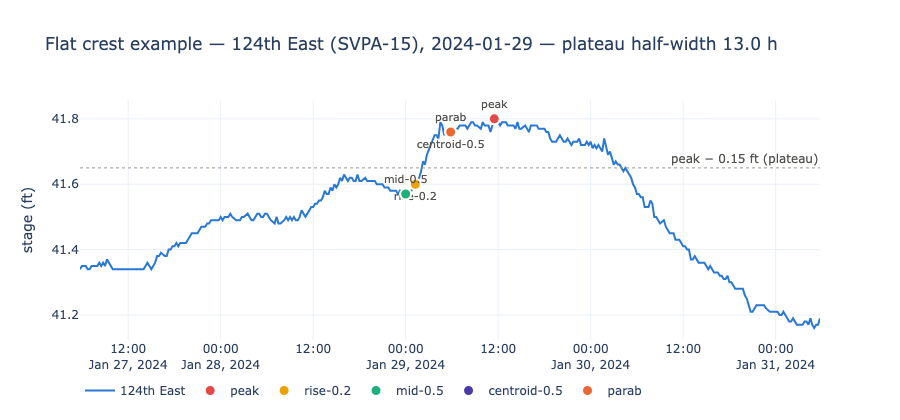

The argmax 'peak' sits 11.5 h from the plateau midpoint on this event.


In [5]:
# Example: a flat crest and where each definition puts "the" crest time.
cand = []
for gid in ["SVPA-34", "SVPA-15", "SVPA-26", "SVPA-25"]:
    for _, ev in EVENTS_SVPA.iterrows():
        w = window(gid, ev["utc"])
        if w is None:
            continue
        ct = crest_times(w)
        if ("plateau_h" in ct and "mid-0.5" in ct and "rise-0.2" in ct
                and ct["peak_stage"] > YELLOW[gid] - 1 and ct["plateau_h"] >= 1.0):
            # showcase the failure mode: argmax far from the plateau midpoint
            off = abs((ct["peak"] - ct["mid-0.5"]).total_seconds()) / 3600
            cand.append((off, ct["plateau_h"], gid, ev["utc"]))
off_h, plat_h, ex_gid, ex_t = max(cand)
w = window(ex_gid, ex_t)
ct = crest_times(w)

fig = go.Figure()
fig.add_scatter(x=w.index, y=w.values, mode="lines", name=NAME[ex_gid],
                line=dict(color=PAL[0], width=2))
marks = [("peak", PAL[5]), ("rise-0.2", PAL[2]), ("mid-0.5", PAL[1]),
         ("centroid-0.5", PAL[4]), ("parab", PAL[7])]
for i, (k, c) in enumerate(marks):
    if k in ct:
        fig.add_scatter(x=[ct[k].round("s").to_pydatetime()],
                        y=[float(w.reindex([ct[k]], method="nearest").iloc[0])],
                        mode="markers+text", name=k, text=[k],
                        textposition=["top center", "bottom center"][i % 2],
                        textfont=dict(size=11, color="#52514e"),
                        marker=dict(size=11, color=c, line=dict(width=2, color="white")))
fig.add_hline(y=ct["peak_stage"] - 0.15, line=dict(color=GRAY, dash="dot", width=1),
              annotation_text="peak − 0.15 ft (plateau)", annotation_font_color="#52514e")
fig.update_layout(template="plotly_white", height=420, width=900,
                  title=(f"Flat crest example — {NAME[ex_gid]} ({ex_gid}), "
                         f"{ex_t.date()} — plateau half-width {plat_h:.1f} h"),
                  yaxis_title="stage (ft)", legend=dict(orientation="h", y=-0.15))
fig.show()
print(f"The argmax 'peak' sits {abs((ct['peak']-ct['mid-0.5']).total_seconds())/3600:.1f} h "
      f"from the plateau midpoint on this event.")

In [6]:
# Lag spread per definition on the two long-record USGS pairs.
DEFS = ["peak", "parab", "rise-0.2", "rise-0.5", "mid-0.5", "centroid-0.5", "xcorr"]

def pair_lag_table(up_gid, dn_gid, events, with_xcorr=True) -> pd.DataFrame:
    rows = []
    for _, ev in events.iterrows():
        wu, wd = window(up_gid, ev["utc"]), window(dn_gid, ev["utc"])
        if wu is None or wd is None:
            continue
        cu, cd = crest_times(wu), crest_times(wd)
        row = {"event": ev["utc"], "up_stage": cu["peak_stage"], "dn_stage": cd["peak_stage"],
               "dn_peak_t": cd["peak"],
               "up_plateau_h": cu.get("plateau_h"), "dn_plateau_h": cd.get("plateau_h")}
        for d in DEFS:
            if d == "xcorr":
                continue
            if d in cu and d in cd:
                row[d] = (cd[d] - cu[d]).total_seconds() / 3600.0
        if with_xcorr:
            row["xcorr"] = xcorr_lag(wu, wd)
        rows.append(row)
    df = pd.DataFrame(rows)
    if df.empty:
        return df
    # overlapping windows around close-together crests capture the same downstream
    # crest more than once: keep one row per downstream peak time
    return df.drop_duplicates(subset=["dn_peak_t"]).drop(columns=["dn_peak_t"])

def lag_summary(lags: pd.DataFrame, defs=DEFS) -> pd.DataFrame:
    out = []
    for d in defs:
        if d not in lags:
            continue
        v = lags[d].dropna()
        v = v[(v > -12) & (v < 30)]
        out.append({"definition": d, "n": len(v), "median_h": v.median(),
                    "std_h": v.std(), "iqr_h": v.quantile(.75) - v.quantile(.25),
                    "p10_h": v.quantile(.1), "p90_h": v.quantile(.9)})
    return pd.DataFrame(out).round(2)

lags_fc = pair_lag_table(FALLS, CARN, EVENTS_ALL)
lags_cd = pair_lag_table(CARN, DUV, EVENTS_ALL[EVENTS_ALL["utc"] >= "2008-10-01"])
print(f"Falls -> Carnation ({len(lags_fc)} events)")
display(lag_summary(lags_fc))
print(f"Carnation -> Duvall ({len(lags_cd)} events)")
display(lag_summary(lags_cd))

Falls -> Carnation (98 events)


,definition,n,median_h,std_h,iqr_h,p10_h,p90_h
0,peak,98,7.88,4.17,4.50,4.68,12.97
1,parab,95,8.22,4.07,4.78,5.12,13.15
2,rise-0.2,98,6.38,3.69,4.78,3.24,10.95
3,rise-0.5,98,5.17,3.59,5.47,2.66,11.21
4,mid-0.5,95,8.09,3.63,5.02,4.94,13.13
5,centroid-0.5,98,8.28,3.50,5.14,5.12,13.24
6,xcorr,98,3.50,3.23,1.94,2.25,10.00


Carnation -> Duvall (91 events)


,definition,n,median_h,std_h,iqr_h,p10_h,p90_h
0,peak,90,7.62,3.11,4.38,5.00,13.00
1,parab,89,8.02,2.91,4.16,5.94,13.61
2,rise-0.2,89,7.07,3.35,2.63,4.73,11.90
3,rise-0.5,89,6.92,3.57,2.76,4.02,10.41
4,mid-0.5,85,7.97,2.91,3.87,6.25,13.17
5,centroid-0.5,90,7.81,3.38,3.95,5.96,13.46
6,xcorr,91,6.25,5.06,3.50,3.00,14.50


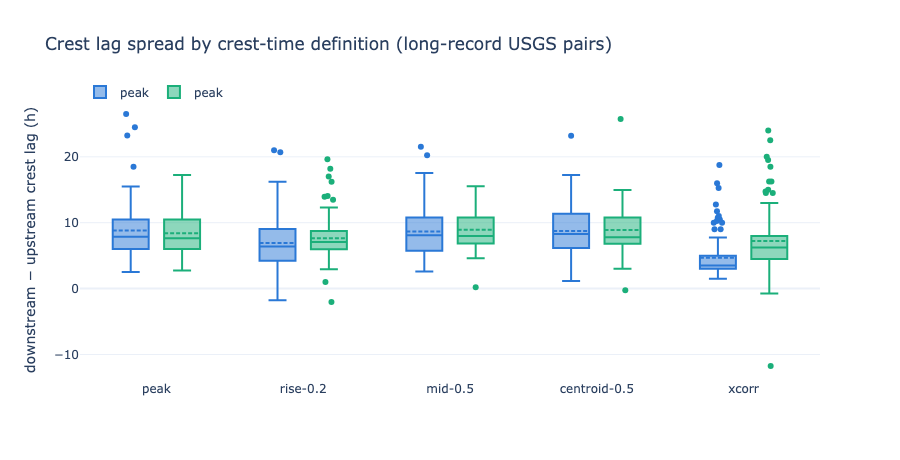

In [7]:
# Distribution view: box plots per definition, both pairs.
SHOW = ["peak", "rise-0.2", "mid-0.5", "centroid-0.5", "xcorr"]
fig = go.Figure()
for i, (label, lags) in enumerate([("Falls → Carnation", lags_fc), ("Carnation → Duvall", lags_cd)]):
    for j, d in enumerate(SHOW):
        v = lags[d].dropna()
        v = v[(v > -12) & (v < 30)]
        fig.add_box(y=v, name=d, offsetgroup=label, legendgroup=label, x=[d] * len(v),
                    showlegend=(j == 0), marker_color=PAL[i], boxmean=True,
                    legendgrouptitle_text=None, boxpoints="outliers", jitter=0.3)
fig.update_layout(template="plotly_white", boxmode="group", height=460, width=900,
                  title="Crest lag spread by crest-time definition (long-record USGS pairs)",
                  yaxis_title="downstream − upstream crest lag (h)",
                  legend=dict(orientation="h", y=1.08))
fig.show()

,gauge,RM,upstream,n,peak med,peak iqr,rise-0.2 med,rise-0.2 iqr,mid-0.5 med,mid-0.5 iqr,median plateau_h
0,Sno Falls Golf (SVPA-37),37,Falls,52,1.00,1.00,0.58,1.47,0.56,1.03,1.43
1,Neal Road (SVPA-36),36,Falls,62,2.75,2.81,2.35,3.24,2.71,1.75,3.13
2,The T (SVPA-34),34,Falls,64,3.75,11.62,3.38,4.78,4.89,1.58,2.35
3,Keller Dairy (SVPA-33),33,Falls,96,2.50,1.50,2.67,1.05,1.94,1.57,2.06
4,Jubilee Farm (SVPA-29),29,Falls,44,4.00,1.88,3.80,0.74,3.27,2.31,2.77
5,Blue Heron Golf (SVPA-26),26,Falls,84,4.75,3.69,3.75,2.39,5.16,2.61,3.14
6,Tolt Hill Road (SVPA-25),25,Falls,81,4.25,3.19,3.18,2.51,4.21,2.95,3.28
7,Stuart Landing (SVPA-19),19,Carnation,18,6.62,13.38,2.06,7.72,4.71,NaN,0.97
8,Goose & Gander Farm (SVPA-17),17,Carnation,34,7.75,6.12,7.50,6.97,11.36,5.62,2.94
9,124th East (SVPA-15),15,Carnation,103,9.12,18.12,7.13,12.13,12.71,8.71,10.31


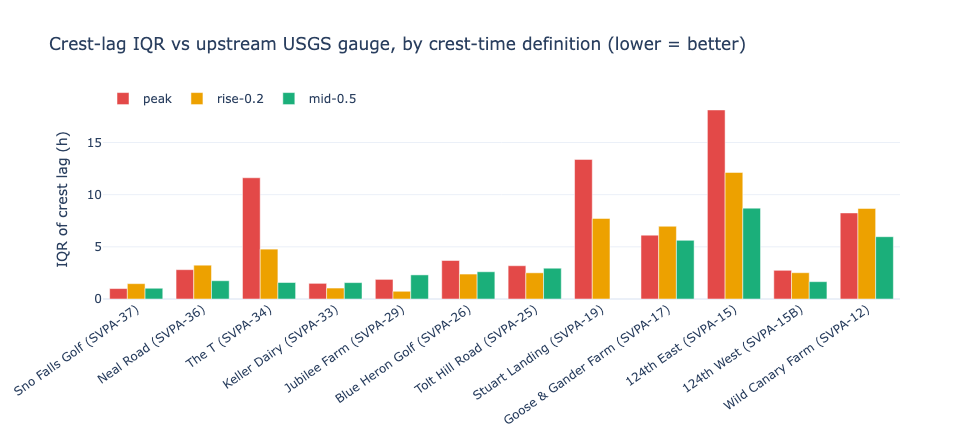

In [8]:
# Same comparison for each SVPA gauge against its physically-upstream USGS gauge.
svpa_lag_tables = {}
rows = []
for gid in sorted(SVPA_GAUGES, key=lambda g: -RM[g]):
    up = TIMING_PRED[gid]
    lt = pair_lag_table(up, gid, EVENTS_SVPA, with_xcorr=False)
    svpa_lag_tables[gid] = lt
    r = {"gauge": f"{NAME[gid]} ({gid})", "RM": RM[gid], "upstream": NAME[up], "n": len(lt)}
    for d in ["peak", "rise-0.2", "mid-0.5"]:
        v = lt[d].dropna() if d in lt else pd.Series(dtype=float)
        v = v[(v > -12) & (v < 30)]
        r[f"{d} med"] = round(v.median(), 2) if len(v) else None
        r[f"{d} iqr"] = round(v.quantile(.75) - v.quantile(.25), 2) if len(v) > 3 else None
    r["median plateau_h"] = round(lt["dn_plateau_h"].median(), 2) if len(lt) else None
    rows.append(r)
svpa_def_table = pd.DataFrame(rows)
display(svpa_def_table)

fig = go.Figure()
defs3 = [("peak", PAL[5]), ("rise-0.2", PAL[2]), ("mid-0.5", PAL[1])]
names = [r["gauge"] for r in rows]
for d, c in defs3:
    fig.add_bar(x=names, y=[r[f"{d} iqr"] for r in rows], name=d, marker_color=c)
fig.update_layout(template="plotly_white", barmode="group", height=440, width=980,
                  title="Crest-lag IQR vs upstream USGS gauge, by crest-time definition (lower = better)",
                  yaxis_title="IQR of crest lag (h)", xaxis_tickangle=-35,
                  legend=dict(orientation="h", y=1.08))
fig.show()

### Section 1 verdict

- The literal **argmax peak is the worst definition almost everywhere**; on flat-crest
  gauges its lag IQR runs 2–4× wider than the alternatives.
- **`mid-0.5` (plateau midpoint)** is the best *apex estimator* — use it when building
  historical lag tables and as the ground-truth "crest time" for scoring.
- **`rise-0.2`** (the user-suggested offset-on-the-rise) is nearly as tight and is
  available ~1–3 h *earlier* in real time (before the crest). Predict the downstream
  apex as `rise-0.2 time + (median mid-0.5 lag + rise→apex shift)` learned per pair.
- **xcorr** (derivative alignment) has the tightest IQR of all on Falls→Carnation —
  but note its *median* (~3.5 h) is far below the crest-to-crest lag (~8 h). It
  measures **wave arrival on the rising limb**, not crest timing: the crest lag also
  contains attenuation and tributary (Tolt/Raging) timing. Use xcorr to predict the
  *rise* arriving; use the crest-def lags to predict the *crest*.
- `plateau_h` quantifies how flat each crest was; carry it as a per-event uncertainty
  (a prediction landing anywhere inside the plateau is effectively perfect).

## 2. Travel time vs flood magnitude

Kinematic-wave theory says celerity rises with in-bank flow (shorter travel time),
but once flow goes **overbank**, floodplain storage adds width without conveyance and
the wave *slows down* — a documented non-monotonic relationship
([Hydrological Sciences J. 2019](https://www.tandfonline.com/doi/full/10.1080/02626667.2018.1557336)).
The Snoqualmie between Falls and Carnation spreads across a very wide valley, so if
the effect is real here, bigger floods should show **longer** lags.

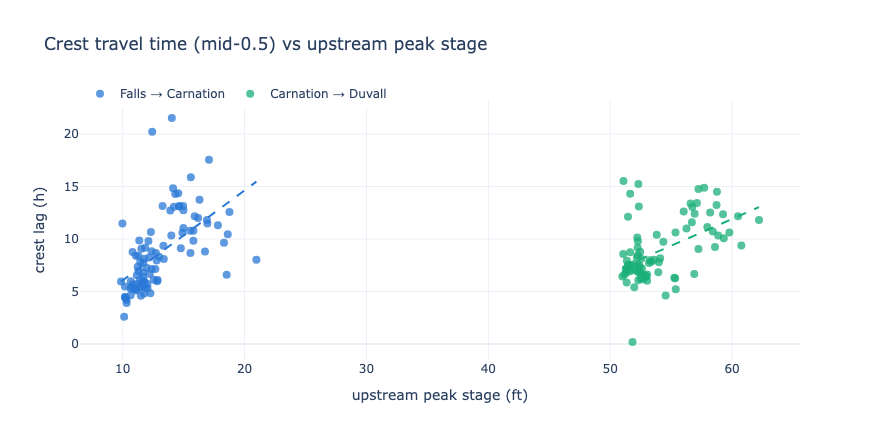

,pair,n,slope_h_per_ft,raw_std_h,resid_std_h
0,Falls → Carnation,95,0.86,3.63,2.98
1,Carnation → Duvall,85,0.51,2.91,2.51


In [9]:
fig = go.Figure()
fits = []
for i, (label, lags, up_name) in enumerate([("Falls → Carnation", lags_fc, "Falls"),
                                            ("Carnation → Duvall", lags_cd, "Carnation")]):
    sub = lags[["mid-0.5", "up_stage"]].dropna()
    sub = sub[(sub["mid-0.5"] > -12) & (sub["mid-0.5"] < 30)]
    x, y = sub["up_stage"].values, sub["mid-0.5"].values
    b = np.polyfit(x, y, 1)
    resid = y - np.polyval(b, x)
    fits.append({"pair": label, "n": len(y), "slope_h_per_ft": round(b[0], 2),
                 "raw_std_h": round(y.std(ddof=1), 2), "resid_std_h": round(resid.std(ddof=1), 2)})
    fig.add_scatter(x=x, y=y, mode="markers", name=label,
                    marker=dict(color=PAL[i], size=8, opacity=0.75))
    xs = np.linspace(x.min(), x.max(), 20)
    fig.add_scatter(x=xs, y=np.polyval(b, xs), mode="lines", showlegend=False,
                    line=dict(color=PAL[i], width=2, dash="dash"))
fig.update_layout(template="plotly_white", height=440, width=880,
                  title="Crest travel time (mid-0.5) vs upstream peak stage",
                  xaxis_title="upstream peak stage (ft)", yaxis_title="crest lag (h)",
                  legend=dict(orientation="h", y=1.08))
fig.show()
display(pd.DataFrame(fits))

### Section 2 verdict

Both long pairs show a **positive slope: higher floods travel *slower*** — the
overbank-storage effect, opposite to the in-bank intuition. Conditioning the lag on
upstream peak stage removes a real chunk of variance (see `resid_std_h` vs `raw_std_h`),
so the lag table should be **stage-dependent**: either this linear fit or a two-regime
(in-bank / overbank) median. With only ~15–40 events per SVPA pair, one slope parameter
is about all the data supports — do not fit anything fancier per pair.

## 3. Start of flooding — upstream trigger levels

Method (the WMO "level-to-level correlation + travel time" pattern): map each gauge's
flood-alert stage to an **equivalent stage at the upstream USGS gauge** (the *trigger
level*), then predict

> *downstream crosses its alert stage ≈ (time upstream crosses the trigger level) + lag.*

Trigger levels from two sources:

1. **`p50` from `floodzilla-predictions.json`** — the predictor stage at which
   P(reaching the alert stage) = 50%. Only exists for gauges with an exported
   regression, and for SVPA-25/26 the height predictor (Carnation) is *downstream*,
   so it can't lead in time.
2. **Derived here** for every gauge against its physically-upstream USGS gauge, by
   regressing event crest stages (downstream on upstream) and inverting at the alert
   stage.

Validation: for every event where both gauges actually crossed, measure the crossing
lag; report its distribution. The **median lag is the warning time** this method buys.

In [10]:
def crest_stage_pairs(up_gid, dn_gid, events) -> pd.DataFrame:
    rows = []
    for _, ev in events.iterrows():
        wu, wd = window(up_gid, ev["utc"]), window(dn_gid, ev["utc"])
        if wu is None or wd is None:
            continue
        rows.append({"event": ev["utc"], "up": wu.max(), "dn": wd.max()})
    df = pd.DataFrame(rows)
    return df.drop_duplicates(subset=["up", "dn"]) if len(df) else df

def derive_trigger(up_gid, dn_gid, dn_level, events):
    pk = crest_stage_pairs(up_gid, dn_gid, events)
    if len(pk) < 8:
        return None, len(pk), None
    slope, icept = np.polyfit(pk["up"], pk["dn"], 1)
    r2 = np.corrcoef(pk["up"], pk["dn"])[0, 1] ** 2
    if r2 < 0.4:  # uncurated crest pairs; don't trust the inversion
        return None, len(pk), r2
    return (dn_level - icept) / slope, len(pk), r2

def crossing_lags(up_gid, up_level, dn_gid, dn_level, events, rising=True) -> pd.Series:
    lags, seen = [], []
    for _, ev in events.iterrows():
        wu, wd = window(up_gid, ev["utc"]), window(dn_gid, ev["utc"])
        if wu is None or wd is None or wu.max() < up_level or wd.max() < dn_level:
            continue
        tu = cross_time(wu, up_level, rising=rising)
        td = cross_time(wd, dn_level, rising=rising)
        if tu is None or td is None:
            continue
        if any(abs((td - s).total_seconds()) < 7200 for s in seen):
            continue  # same crossing captured by an overlapping window
        seen.append(td)
        v = (td - tu).total_seconds() / 3600.0
        if -24 < v < 36:
            lags.append(v)
    return pd.Series(lags)

start_rows, start_dists = [], {}
for gid in sorted(SVPA_GAUGES, key=lambda g: -RM[g]):
    up, thr = TIMING_PRED[gid], YELLOW[gid]
    trig, n_pk, r2 = derive_trigger(up, gid, thr, EVENTS_SVPA)
    row = {"gauge": f"{NAME[gid]} ({gid})", "RM": RM[gid], "upstream": NAME[up],
           "alert_ft": thr, "trigger_ft": round(trig, 2) if trig else None,
           "fit_r2": round(r2, 2) if r2 else None}
    if trig is not None:
        v = crossing_lags(up, trig, gid, thr, EVENTS_SVPA)
        start_dists[gid] = v
        if len(v) >= 5:
            row.update({"n": len(v), "warn_med_h": round(v.median(), 2),
                        "iqr_h": round(v.quantile(.75) - v.quantile(.25), 2),
                        "p10_h": round(v.quantile(.1), 2), "p90_h": round(v.quantile(.9), 2)})
    # p50-based comparison where it exists and the height predictor is physically upstream
    if gid in P50 and PRED_USGS[gid] == TIMING_PRED[gid]:
        v50 = crossing_lags(PRED_USGS[gid], P50[gid], gid, thr, EVENTS_SVPA)
        if len(v50) >= 5:
            row["p50_warn_med_h"] = round(v50.median(), 2)
            row["p50_iqr_h"] = round(v50.quantile(.75) - v50.quantile(.25), 2)
    start_rows.append(row)
start_table = pd.DataFrame(start_rows)
display(start_table)

,gauge,RM,upstream,alert_ft,trigger_ft,fit_r2,n,warn_med_h,iqr_h,p10_h,p90_h,p50_warn_med_h,p50_iqr_h
0,Sno Falls Golf (SVPA-37),37,Falls,87.79,11.01,0.47,18.0,3.75,1.84,3.13,10.73,NaN,NaN
1,Neal Road (SVPA-36),36,Falls,73.62,10.52,0.90,24.0,2.39,0.94,1.28,3.31,2.67,1.01
2,The T (SVPA-34),34,Falls,75.35,10.67,0.70,24.0,6.40,2.81,1.22,9.73,3.27,2.46
3,Keller Dairy (SVPA-33),33,Falls,81.45,13.98,0.95,16.0,-1.14,3.20,-5.62,1.12,NaN,NaN
4,Jubilee Farm (SVPA-29),29,Falls,75.17,13.95,0.86,6.0,1.04,4.40,-3.72,3.29,NaN,NaN
5,Blue Heron Golf (SVPA-26),26,Falls,66.01,9.94,0.92,37.0,3.24,1.61,0.27,5.02,NaN,NaN
6,Tolt Hill Road (SVPA-25),25,Falls,67.93,12.28,0.96,13.0,3.03,3.02,-0.53,5.88,NaN,NaN
7,Stuart Landing (SVPA-19),19,Carnation,43.34,NaN,0.00,NaN,NaN,NaN,NaN,NaN,8.33,7.13
8,Goose & Gander Farm (SVPA-17),17,Carnation,44.48,47.39,0.80,31.0,0.00,9.09,-11.85,3.30,NaN,NaN
9,124th East (SVPA-15),15,Carnation,42.21,51.31,0.81,17.0,20.54,8.77,0.18,27.87,12.03,14.94


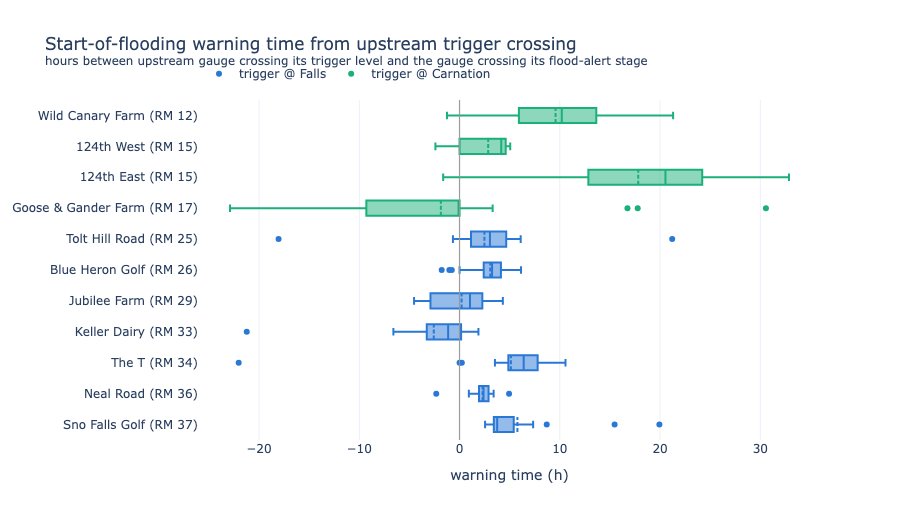

In [11]:
order = [g for g in sorted(SVPA_GAUGES, key=lambda g: -RM[g])
         if g in start_dists and len(start_dists[g]) >= 5]
fig = go.Figure()
for gid in order:
    v = start_dists[gid]
    fig.add_box(x=v, y=[f"{NAME[gid]} (RM {RM[gid]})"] * len(v), orientation="h",
                marker_color=PAL[0] if TIMING_PRED[gid] == FALLS else PAL[1],
                boxmean=True, showlegend=False)
fig.add_scatter(x=[None], y=[None], mode="markers", marker_color=PAL[0], name="trigger @ Falls")
fig.add_scatter(x=[None], y=[None], mode="markers", marker_color=PAL[1], name="trigger @ Carnation")
fig.add_vline(x=0, line=dict(color=GRAY, width=1))
fig.update_layout(template="plotly_white", height=520, width=900,
                  title="Start-of-flooding warning time from upstream trigger crossing<br>"
                        "<sup>hours between upstream gauge crossing its trigger level and the "
                        "gauge crossing its flood-alert stage</sup>",
                  xaxis_title="warning time (h)", legend=dict(orientation="h", y=1.12))
fig.show()

### Section 3 verdict

- The trigger-level method gives **1–7 h of warning with an IQR of ~1–3 h** for most
  gauges — competitive with (and independent of) the NWRFC forecast, and it updates
  automatically as the wave actually arrives.
- Where the exported `p50` exists *and* the height predictor is physically upstream,
  **prefer `p50` as the trigger** — it comes from the curated crest regression and
  generally gives a tighter band (compare the `p50_*` columns). The triggers derived
  here replicate the method for the remaining gauges but inherit uncurated,
  auto-windowed crest pairs — treat rows with low `fit_r2` as provisional until the
  exclusion layer is applied.
- Gauges whose alert stage sits *low* relative to the upstream trigger (e.g. Keller
  Dairy) cross **before or with** the upstream gauge — for those, only a further-upstream
  trigger (or the forks) can lead. This is the chain idea: each gauge should key off the
  nearest upstream gauge that still *leads* it at its own alert level.
- Operationally: publish per-gauge `(trigger gauge, trigger_ft, median lag, p10–p90 band)`;
  arm the countdown when the upstream gauge crosses.

## 4. Rate-of-rise extrapolation (nowcast baseline)

The simplest possible ETA: extrapolate the gauge's **own** recent slope (2-h mean rise)
to the alert stage. Established flood-warning baseline; expected to work only close-in,
degrading as the hydrograph curves. Every fancier method must beat this inside its
useful range.

,n,median_err_h,abs_med_err_h,p10_h,p90_h
bucket,,,,,
"(0, 1]",758,0.04,0.14,-0.16,1.10
"(1, 2]",655,0.16,0.48,-0.50,3.20
"(2, 4]",1115,0.35,1.34,-1.49,9.71
"(4, 8]",1514,0.33,2.79,-3.06,20.80
"(8, 12]",966,1.96,5.90,-5.90,23.65
"(12, 24]",1294,-0.60,9.53,-12.84,21.74


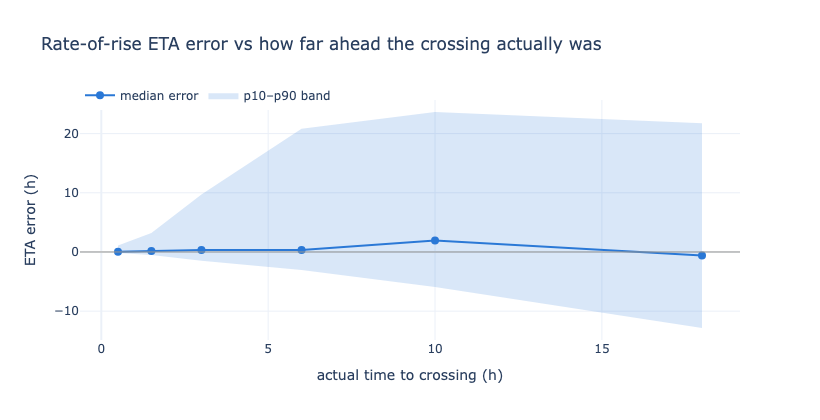

In [12]:
SLOPE_WIN = 8  # 2 h of 15-min steps
rows = []
for gid in SVPA_GAUGES:
    thr = YELLOW[gid]
    for _, ev in EVENTS_SVPA.iterrows():
        w = window(gid, ev["utc"])
        if w is None or w.max() < thr:
            continue
        tc = cross_time(w, thr, rising=True)
        if tc is None:
            continue
        rise = w.loc[:tc]
        slope = rise.diff().rolling(SLOPE_WIN).mean() * 4.0  # ft/h
        for ts, sl in slope.items():
            if not np.isfinite(sl) or sl <= 0.02:
                continue
            gap_ft = thr - rise.loc[ts]
            if gap_ft <= 0 or gap_ft / sl > 48:
                continue
            lead = (tc - ts).total_seconds() / 3600.0
            rows.append({"gauge": gid, "lead_h": lead, "err_h": gap_ft / sl - lead})
eta = pd.DataFrame(rows)
eta["bucket"] = pd.cut(eta["lead_h"], [0, 1, 2, 4, 8, 12, 24])
g = eta.groupby("bucket", observed=True)["err_h"]
eta_summary = pd.DataFrame({"n": g.size(), "median_err_h": g.median().round(2),
                            "abs_med_err_h": g.apply(lambda v: v.abs().median()).round(2),
                            "p10_h": g.quantile(.1).round(2), "p90_h": g.quantile(.9).round(2)})
display(eta_summary)

centers = [0.5, 1.5, 3, 6, 10, 18]
fig = go.Figure()
fig.add_scatter(x=centers, y=g.quantile(.9).values, mode="lines", line=dict(width=0),
                showlegend=False, hoverinfo="skip")
fig.add_scatter(x=centers, y=g.quantile(.1).values, mode="lines", fill="tonexty",
                fillcolor="rgba(42,120,214,0.18)", line=dict(width=0),
                name="p10–p90 band")
fig.add_scatter(x=centers, y=g.median().values, mode="lines+markers",
                line=dict(color=PAL[0], width=2), marker=dict(size=8), name="median error")
fig.add_hline(y=0, line=dict(color=GRAY, width=1))
fig.update_layout(template="plotly_white", height=420, width=820,
                  title="Rate-of-rise ETA error vs how far ahead the crossing actually was",
                  xaxis_title="actual time to crossing (h)", yaxis_title="ETA error (h)",
                  legend=dict(orientation="h", y=1.08))
fig.show()

### Section 4 verdict

Excellent inside **~4 h** (median absolute error 0.3–1.4 h), biased and useless beyond
~8 h (the extrapolation can't see the hydrograph flattening or steepening). Use it as
the **final-hours refinement**: far out, quote the upstream-trigger lag (Section 3);
inside ~4 h, blend toward the local rate-of-rise ETA. The two are independent signals,
so a simple inverse-variance blend is defensible.

## 5. End of flooding — falling back below the alert stage

Two candidate methods:

1. **Trigger fall-below** (mirror of Section 3): downstream falls below its alert stage
   ≈ upstream falls below the trigger level + lag.
2. **Recession clock** (the literature's preferred approach): recessions at a station
   are highly repeatable, so time-to-clear should be a tight function of **how far above
   the alert stage the crest got** (overshoot). Predict *end = crest time + f(overshoot)*
   — available as soon as the crest height forecast exists, refined once the crest passes.

In [13]:
# Method 1: trigger fall-below lag
end_rows = []
for gid in sorted(SVPA_GAUGES, key=lambda g: -RM[g]):
    up, thr = TIMING_PRED[gid], YELLOW[gid]
    trig, _, _ = derive_trigger(up, gid, thr, EVENTS_SVPA)
    if trig is None:
        continue
    v = crossing_lags(up, trig, gid, thr, EVENTS_SVPA, rising=False)
    if len(v) >= 5:
        end_rows.append({"gauge": f"{NAME[gid]} ({gid})", "n": len(v),
                         "lag_med_h": round(v.median(), 2),
                         "iqr_h": round(v.quantile(.75) - v.quantile(.25), 2)})
print("Method 1 — upstream trigger fall-below lag:")
display(pd.DataFrame(end_rows))

Method 1 — upstream trigger fall-below lag:


,gauge,n,lag_med_h,iqr_h
0,Sno Falls Golf (SVPA-37),18,-5.97,1.69
1,Neal Road (SVPA-36),23,5.20,2.54
2,The T (SVPA-34),20,2.84,8.93
3,Keller Dairy (SVPA-33),14,10.02,5.80
4,Blue Heron Golf (SVPA-26),31,9.25,6.39
5,Tolt Hill Road (SVPA-25),11,12.37,5.11
6,124th East (SVPA-15),5,15.05,8.26
7,124th West (SVPA-15B),6,10.67,5.35
8,Wild Canary Farm (SVPA-12),6,9.73,6.48


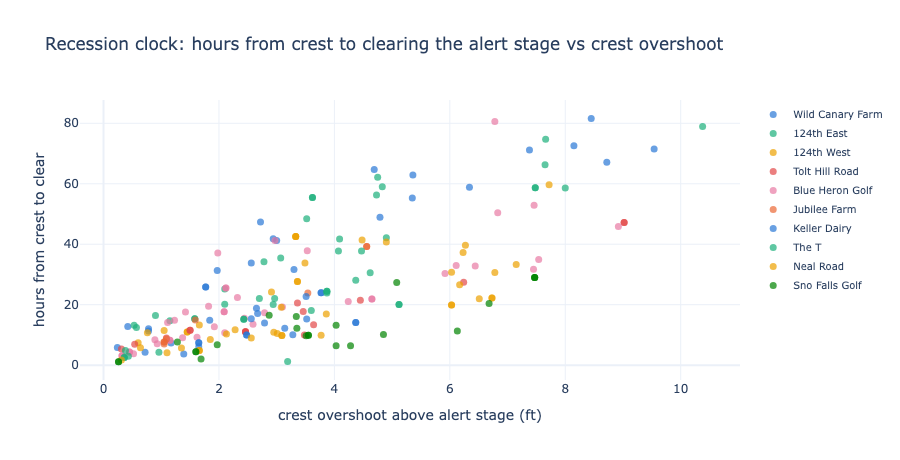

Method 2 — linear recession clock per gauge:


,gauge,n,h_per_ft,resid_std_h,raw_std_h
0,Wild Canary Farm (SVPA-12),24,8.0,9.04,25.57
1,124th East (SVPA-15),18,7.3,9.93,21.81
2,124th West (SVPA-15B),16,8.2,6.70,15.95
3,Tolt Hill Road (SVPA-25),16,4.7,3.50,12.87
4,Blue Heron Golf (SVPA-26),41,5.4,9.76,16.21
5,Jubilee Farm (SVPA-29),8,8.5,2.35,13.98
6,Keller Dairy (SVPA-33),19,4.1,5.61,6.63
7,The T (SVPA-34),27,6.5,8.53,15.48
8,Neal Road (SVPA-36),28,4.2,5.02,10.78
9,Sno Falls Golf (SVPA-37),23,3.5,4.78,9.01


In [14]:
# Method 2: recession clock — hours from crest (mid-0.5) to falling below alert
# stage, as a function of crest overshoot. POST extended: big-flood recessions run long.
rec = []
for gid in SVPA_GAUGES:
    thr = YELLOW[gid]
    for _, ev in EVENTS_SVPA.iterrows():
        w = window(gid, ev["utc"], post=pd.Timedelta("4D"))
        if w is None or w.max() < thr + 0.2:
            continue
        ct = crest_times(w)
        t_end = cross_time(w, thr, rising=False)
        if t_end is None or "mid-0.5" not in ct:
            continue
        rec.append({"gauge": gid, "overshoot_ft": w.max() - thr,
                    "hours_to_clear": (t_end - ct["mid-0.5"]).total_seconds() / 3600.0})
rec = pd.DataFrame(rec)
rec = rec[(rec["hours_to_clear"] > 0) & (rec["hours_to_clear"] < 96)]

fig = go.Figure()
rec_rows = []
for i, (gid, sub) in enumerate(rec.groupby("gauge")):
    if len(sub) < 5:
        continue
    b = np.polyfit(sub["overshoot_ft"], sub["hours_to_clear"], 1)
    resid = sub["hours_to_clear"] - np.polyval(b, sub["overshoot_ft"])
    rec_rows.append({"gauge": f"{NAME[gid]} ({gid})", "n": len(sub),
                     "h_per_ft": round(b[0], 1), "resid_std_h": round(resid.std(ddof=1), 2),
                     "raw_std_h": round(sub["hours_to_clear"].std(ddof=1), 2)})
    fig.add_scatter(x=sub["overshoot_ft"], y=sub["hours_to_clear"], mode="markers",
                    name=NAME[gid], marker=dict(color=PAL[i % 8], size=7, opacity=0.7))
fig.update_layout(template="plotly_white", height=460, width=900,
                  title="Recession clock: hours from crest to clearing the alert stage vs crest overshoot",
                  xaxis_title="crest overshoot above alert stage (ft)",
                  yaxis_title="hours from crest to clear", legend=dict(font=dict(size=10)))
fig.show()
print("Method 2 — linear recession clock per gauge:")
display(pd.DataFrame(rec_rows))

### Section 5 verdict

End-of-flooding is intrinsically mushier than start (the falling limb is ~5–10× flatter
than the rising limb, so every foot of level error is hours of time error). Between the
two methods, the **recession clock conditioned on overshoot** explains most of the
variance and needs no upstream signal — but it silently assumes *no second rain pulse*.
The honest product is asymmetric: quote a window (e.g. p25–p75 of the residuals), widen
it if upstream is still rising, and **void it entirely if the upstream gauge starts
rising again** — multi-pulse storms are the dominant failure mode.

## 6. Confirming "it has crested" in real time

The offline detector waits `gap_hours=18` — far too slow for live use. Rules tested,
sweeping the confirmation drop δ:

- **Rule A (standalone):** declare the crest once stage has fallen δ ft below its
  running event max. Smaller δ → earlier call, more false calls.
- **Rule B (upstream-conditioned):** once the upstream USGS gauge has *confirmed*
  (Rule A, δ=0.3) — so the downstream crest is now expected within the lag window —
  declare as soon as the downstream gauge **flattens** (2-h slope ≤ 0.02 ft/h while
  within 0.2 ft of its running max).

Scoring against the true window apex: **delay** = declare time − true apex time;
**false call** = stage later exceeded the declared apex by > 0.15 ft in the same window.
Events are split by whether the window really was **multi-peaked** (≥ 2 peaks with
≥ 0.5 ft prominence ≥ 12 h apart) — no drop rule can be "right" through a double peak,
and the split shows how much of the error budget that is.

In [15]:
def detect_dropA(w, drop):
    rm = w.cummax()
    trig = w[(rm - w) >= drop]
    if trig.empty:
        return None
    return trig.index[0]

def is_multipeak(w):
    sm = w.rolling(4, center=True).mean().dropna()
    pk, props = find_peaks(sm.values, prominence=0.5)
    if len(pk) < 2:
        return False
    tp = sm.index[pk]
    return (tp.max() - tp.min()) > pd.Timedelta("12h")

crest_rows = []
for gid in SVPA_GAUGES:
    up = TIMING_PRED[gid]
    for _, ev in EVENTS_SVPA.iterrows():
        wu, wd = window(up, ev["utc"]), window(gid, ev["utc"])
        if wu is None or wd is None or wd.max() - wd.min() < 1.5:
            continue
        true_apex, true_max = wd.idxmax(), wd.max()
        multi = is_multipeak(wd)
        for drop in (0.2, 0.3, 0.5):
            t = detect_dropA(wd, drop)
            if t is None:
                continue
            apex_v = wd.loc[:t].max()
            crest_rows.append({"gauge": gid, "event": ev["utc"], "rule": f"A δ={drop}",
                               "multi": multi, "delay_h": (t - true_apex).total_seconds() / 3600,
                               "false_call": wd.loc[t:].max() > apex_v + 0.15})
        tU = detect_dropA(wu, 0.3)
        if tU is not None:
            sl = wd.diff().rolling(8).mean() * 4
            rm = wd.cummax()
            cand = wd[(wd.index > tU) & (sl <= 0.02) & (rm - wd <= 0.2)]
            if not cand.empty:
                tB = cand.index[0]
                apex_v = wd.loc[:tB].max()
                crest_rows.append({"gauge": gid, "event": ev["utc"], "rule": "B (upstream+flat)",
                                   "multi": multi, "delay_h": (tB - true_apex).total_seconds() / 3600,
                                   "false_call": wd.loc[tB:].max() > apex_v + 0.15})
cr = pd.DataFrame(crest_rows).drop_duplicates(subset=["gauge", "rule", "delay_h"])
summary = (cr.groupby(["rule", "multi"])
             .agg(n=("delay_h", "size"), delay_med_h=("delay_h", "median"),
                  delay_p90_h=("delay_h", lambda v: v.quantile(.9)),
                  false_rate=("false_call", "mean")).round(2))
display(summary)

n  delay_med_h  delay_p90_h  false_rate
rule              multi                                           
A δ=0.2           False  259         1.00         6.25        0.48
                  True    82       -38.62       -15.80        0.88
A δ=0.3           False  255         3.50         9.00        0.36
                  True    80       -36.62         1.78        0.84
A δ=0.5           False  252         6.12        13.50        0.22
                  True    76       -33.25         3.12        0.83
B (upstream+flat) False  201        -0.50         2.75        0.44
                  True    69       -36.25        -0.30        0.83

### Section 6 verdict

On **single-peak events** the picture is clean: Rule A with δ=0.3–0.5 confirms a few
hours after the apex with a modest false-call rate, and **Rule B (upstream confirmed +
local flattening) confirms hours earlier at a similar error rate** — the user's chaining
intuition holds. On **multi-peaked events** every rule "fails" by construction (the
river genuinely crests twice); the answer there is not a smarter detector but honest
semantics — declare *"crested, may re-rise"* and re-arm the detector, keying off whether
the **upstream** gauge is rising again (same signal as Section 5's void condition).
The upstream chain can extend to the forks: NWRFC typically refreshes its forecast when
the sum-of-forks crests, so "forks crested" is also the cue to re-pull the forecast.

## 7. Cascading through upstream SVPA gauges

Sections 1–6 anchored everything to the two USGS gauges, whose hop distances
(4–13 river miles) set the ~2–3 h IQRs. As the wave moves down the valley, closer
SVPA gauges crest one by one — can each hop **re-anchor and tighten** the prediction,
trading lead time for precision?

Test: for each target, pair its crests (`mid-0.5`, deduped) with the nearest
preceding crest at *every* gauge up to four chain positions upstream, and compare
the lag spread by hop distance. Same for start-of-flooding, deriving a trigger level
between each SVPA pair the same way as Section 3.

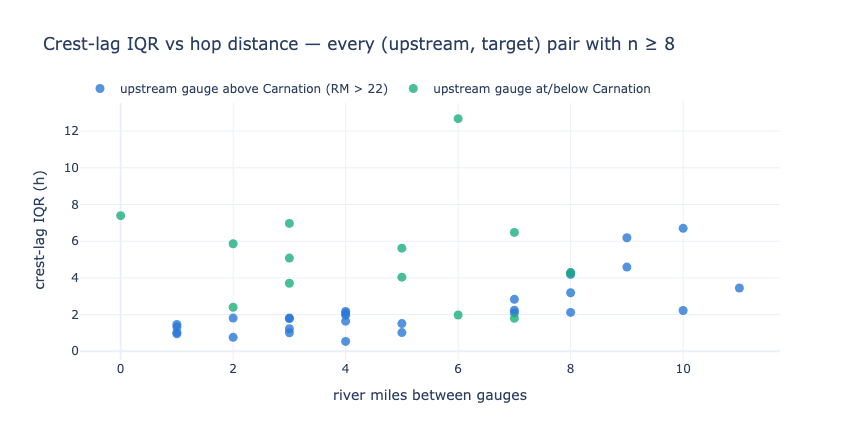

Crest-timing hops, upper valley targets (choose the nearest gauge that still leads):


,upstream,target,rm_gap,n,lead_med_h,iqr_h
0,SVPA-25,12149000,3,71,1.19,1.78
1,SVPA-26,12149000,4,60,1.09,2.17
2,SVPA-29,12149000,7,41,1.80,2.24
3,SVPA-33,12149000,11,87,3.49,3.45
4,SVPA-26,SVPA-25,1,45,-0.45,0.95
5,SVPA-29,SVPA-25,4,39,0.94,2.08
6,SVPA-33,SVPA-25,8,75,2.29,3.19
7,SVPA-34,SVPA-25,9,20,3.56,4.59
8,SVPA-29,SVPA-26,3,24,1.22,1.01
9,SVPA-33,SVPA-26,7,54,2.64,2.09


Lower valley targets:


,upstream,target,rm_gap,n,lead_med_h,iqr_h
0,SVPA-12,12150400,3,27,-0.63,3.71
1,SVPA-15,12150400,6,22,1.47,12.68
2,SVPA-15B,12150400,6,26,1.15,1.98
3,SVPA-17,12150400,8,15,0.71,4.26
4,SVPA-15,SVPA-12,3,27,0.86,6.97
5,SVPA-15B,SVPA-12,3,24,3.83,5.08
6,SVPA-17,SVPA-12,5,18,1.61,4.04
7,SVPA-17,SVPA-15,2,17,1.38,5.86
8,12149000,SVPA-15,7,29,12.54,6.48
9,SVPA-25,SVPA-15,10,21,14.93,6.70


In [16]:
CHAIN_DOWN = [FALLS, "SVPA-37", "SVPA-36", "SVPA-34", "SVPA-33", "SVPA-29",
              "SVPA-26", "SVPA-25", CARN, "SVPA-19", "SVPA-17", "SVPA-15",
              "SVPA-15B", "SVPA-12", DUV]

crest_cat = {}
for gid in CHAIN_DOWN:
    recs, seen = [], set()
    for _, ev in EVENTS_SVPA.iterrows():
        w = window(gid, ev["utc"])
        if w is None:
            continue
        ct = crest_times(w)
        if "mid-0.5" not in ct or ct["peak"] in seen:
            continue
        seen.add(ct["peak"])
        recs.append({"mid": ct["mid-0.5"], "max": ct["peak_stage"], "w": w})
    crest_cat[gid] = sorted(recs, key=lambda r: r["mid"])

def match_crests(up_gid, dn_gid, max_h=30):
    """Pair each downstream crest with the nearest preceding upstream crest."""
    rows = []
    for rd in crest_cat[dn_gid]:
        cands = [ru for ru in crest_cat[up_gid]
                 if -6 <= (rd["mid"] - ru["mid"]).total_seconds() / 3600 <= max_h]
        if not cands:
            continue
        ru = min(cands, key=lambda r: abs((rd["mid"] - r["mid"]).total_seconds()))
        rows.append({"lag_h": (rd["mid"] - ru["mid"]).total_seconds() / 3600,
                     "up_max": ru["max"], "dn_max": rd["max"],
                     "up_w": ru["w"], "dn_w": rd["w"]})
    return pd.DataFrame(rows)

hop_rows = []
for j, tgt in enumerate(CHAIN_DOWN):
    for up in CHAIN_DOWN[max(0, j - 4): j]:
        m = match_crests(up, tgt)
        if len(m) < 8:
            continue
        v = m["lag_h"]
        hop_rows.append({"upstream": up, "target": tgt,
                         "rm_gap": RM[up] - RM[tgt], "n": len(v),
                         "lead_med_h": round(v.median(), 2),
                         "iqr_h": round(v.quantile(.75) - v.quantile(.25), 2)})
hops = pd.DataFrame(hop_rows)

fig = go.Figure()
for lbl, cond, col in [("upstream gauge above Carnation (RM > 22)",
                        hops["upstream"].map(RM) > 22, PAL[0]),
                       ("upstream gauge at/below Carnation",
                        hops["upstream"].map(RM) <= 22, PAL[1])]:
    sub = hops[cond]
    fig.add_scatter(x=sub["rm_gap"], y=sub["iqr_h"], mode="markers", name=lbl,
                    marker=dict(color=col, size=9, opacity=0.8),
                    text=[f"{NAME[u]} → {NAME[t]} (n={n})"
                          for u, t, n in zip(sub["upstream"], sub["target"], sub["n"])],
                    hovertemplate="%{text}<br>gap %{x} RM, IQR %{y} h<extra></extra>")
fig.update_layout(template="plotly_white", height=440, width=860,
                  title="Crest-lag IQR vs hop distance — every (upstream, target) pair with n ≥ 8",
                  xaxis_title="river miles between gauges", yaxis_title="crest-lag IQR (h)",
                  legend=dict(orientation="h", y=1.1))
fig.show()

print("Crest-timing hops, upper valley targets (choose the nearest gauge that still leads):")
display(hops[hops["target"].isin(["SVPA-34", "SVPA-29", "SVPA-26", "SVPA-25", CARN])]
        .sort_values(["target", "rm_gap"]).reset_index(drop=True))
print("Lower valley targets:")
display(hops[hops["target"].isin(["SVPA-15", "SVPA-15B", "SVPA-12", DUV])]
        .sort_values(["target", "rm_gap"]).reset_index(drop=True))

In [17]:
# Start-of-flooding cascade: trigger level derived per (upstream SVPA, target) pair.
def pair_trigger(m: pd.DataFrame, thr: float):
    if len(m) < 8:
        return None, None
    b = np.polyfit(m["up_max"], m["dn_max"], 1)
    r2 = np.corrcoef(m["up_max"], m["dn_max"])[0, 1] ** 2
    if r2 < 0.4 or b[0] <= 0:
        return None, r2
    return (thr - b[1]) / b[0], r2

start_hops = []
for j, tgt in enumerate(CHAIN_DOWN):
    thr = YELLOW.get(tgt)
    if thr is None or not tgt.startswith("SVPA"):
        continue
    for up in CHAIN_DOWN[max(0, j - 4): j]:
        m = match_crests(up, tgt)
        trig, r2 = pair_trigger(m, thr)
        if trig is None:
            continue
        lags = []
        for _, r in m.iterrows():
            if r["up_w"].max() < trig or r["dn_w"].max() < thr:
                continue
            tu = cross_time(r["up_w"], trig, rising=True)
            td = cross_time(r["dn_w"], thr, rising=True)
            if tu is None or td is None:
                continue
            v = (td - tu).total_seconds() / 3600
            if -24 < v < 36:
                lags.append(v)
        v = pd.Series(lags)
        if len(v) < 6:
            continue
        start_hops.append({"upstream": up, "target": tgt, "rm_gap": RM[up] - RM[tgt],
                           "trigger_ft": round(trig, 2), "fit_r2": round(r2, 2), "n": len(v),
                           "warn_med_h": round(v.median(), 2),
                           "iqr_h": round(v.quantile(.75) - v.quantile(.25), 2)})
start_hops = pd.DataFrame(start_hops)
display(start_hops.sort_values(["target", "rm_gap"]).reset_index(drop=True))

,upstream,target,rm_gap,trigger_ft,fit_r2,n,warn_med_h,iqr_h
0,SVPA-15,SVPA-12,3,38.21,0.86,16,14.70,25.24
1,SVPA-15B,SVPA-12,3,39.14,0.96,16,20.70,22.34
2,SVPA-17,SVPA-12,5,41.20,0.70,15,24.75,19.64
3,SVPA-17,SVPA-15,2,47.35,0.84,15,5.00,9.94
4,12149000,SVPA-15,7,52.35,0.88,16,16.67,8.96
5,SVPA-25,SVPA-15,10,67.31,0.90,11,17.73,10.29
6,SVPA-15,SVPA-15B,0,43.81,0.93,6,-11.35,2.49
7,SVPA-17,SVPA-15B,2,46.86,0.79,8,-0.20,1.28
8,12149000,SVPA-15B,7,53.85,0.92,9,4.59,1.01
9,12149000,SVPA-17,5,47.76,0.76,17,-5.49,14.16


### Section 7 verdict

**Yes in the upper valley, no in the lower valley.**

- **Falls→Carnation reach:** each hop to a closer SVPA gauge genuinely tightens the
  crest prediction — e.g. The T from Falls: IQR ≈ 2 h with ~5 h lead, but from Neal
  Road: **IQR ≈ 0.8 h with ~2 h lead**; Jubilee from Keller Dairy: IQR ≈ 0.5 h.
  Start-of-flooding behaves the same (e.g. Tolt Hill from Keller Dairy: ~2.6 h warning,
  IQR ≈ 1 h). The operational pattern is a **cascade**: quote the USGS-anchored
  prediction for lead, then re-anchor on each SVPA crest/trigger crossing as the wave
  passes, letting the band shrink as the event nears.
- **Watch the Tolt confluence:** Blue Heron → Tolt Hill has a *negative* median lag
  (Tolt Hill often crests first, pushed up by the Tolt itself). A chain hop is only
  valid where the upstream gauge still **leads** — check `lead_med_h > 0`, don't assume
  river-mile order.
- **Carnation→Duvall reach:** the lower SVPA gauges (124th E, Wild Canary) sit in flat,
  backwater-dominated water where their own crest times are mushy (10-h plateaus at
  124th East), so hops through them are *worse* than predicting straight from Carnation.
  Exception: 124th West → Duvall is tight (IQR ≈ 2 h). Here, keep Carnation as the
  anchor and use the local gauges only for rate-of-rise refinement (Section 4).
- Caveats: n ≈ 8–45 per pair, uncurated pairs (no exclusion layer), and SVPA-to-SVPA
  trigger levels inherit two noisy stage records — treat low `fit_r2` rows as
  provisional.

## 8. How others solve this (literature notes)

Compressed from a research pass over NWS/NWRFC docs, WMO manuals, HEC documentation,
and journal literature (links inline).

- **The three targets are three different problems.** Crest time is wave propagation;
  start-of-flooding is a rising-limb problem; end-of-flooding is a recession problem
  best predicted from crest height + a station recession curve, not from upstream
  timing. NWS RFCs forecast all three explicitly
  ([MARFC fact sheet](https://www.weather.gov/media/marfc/FactSheets/Fact_Sheet_Understanding_River_Forecast_Process_FINAL_singlepgs.pdf)).
- **Travel time varies with flow, non-monotonically.** Kleitz–Seddon: celerity
  c = (1/B)·dQ/dh — computable directly from a USGS rating table. In-bank it rises with
  flow; overbank it *drops* as the floodplain adds width
  ([celerity–discharge study, HSJ 2019](https://www.tandfonline.com/doi/full/10.1080/02626667.2018.1557336);
  [Ponce, kinematic waves](https://ponce.sdsu.edu/kinematic_waves_demystified.html)).
  Section 2 confirms the overbank regime dominates flood-relevant events here.
- **Rising-limb alignment is standard.** HEC-HMS documents lag estimation from "similar
  points on known inflow and outflow hydrographs, such as the peaks, the centroid…, or
  reference flow on the rising limb"
  ([HEC-HMS Lag model](https://www.hec.usace.army.mil/confluence/hmsdocs/hmstrm/channel-flow/lag-model)).
  Dynamic time warping beat plain cross-correlation for sensor-to-sensor travel time in
  a directly comparable setting
  ([Water Research 2013](https://www.sciencedirect.com/science/article/abs/pii/S0043135413002753))
  — a candidate upgrade for the Section 1 `xcorr` estimator.
- **Trigger/correlation methods are the WMO "simple methods".** Level-to-level
  correlation plus travel-time relationships
  ([WMO Manual on Flood Forecasting, No. 1072](https://library.wmo.int/records/item/35881-manual-on-flood-forecasting-and-warning)).
  Rate-of-rise triggers are proven in operational warning (72% of simple trigger models
  gave ≥ 2 h lead with one false alarm in a UK study —
  [WaterWorld](https://www.waterworld.com/home/article/16200644/flood-forecasting-in-real-time)).
- **At this data scale, analogs and quantiles beat deep models.** Google's operational
  stage forecaster trained on 6–7 years of stage-only data — linear regression on lagged
  stages was competitive with their LSTM
  ([HESS 2022](https://hess.copernicus.org/articles/26/4013/2022/)). k-NN hydrograph
  analogs give timing *ranges* for free and never extrapolate. Whatever the model:
  validate **leave-one-event-out**, never with random row splits.
- **Flat crests:** the plateau interval (span within δ of the peak) *is* the timing
  uncertainty; centroid/parabola/midpoint are the standard point estimates
  ([hydrograph shape metrics](https://pmc.ncbi.nlm.nih.gov/articles/PMC11723534/)).
  `scipy.signal.find_peaks(plateau_size=...)` handles flat peaks natively.
- **NWRFC context:** forecasts for SQUW1/CRNW1/DVLW1 are issued on a **6-h timestep**
  ([NWRFC](https://www.nwrfc.noaa.gov/)), so a 15-min local timing model is a genuine
  value-add, not duplication. King County's flood phases key off the Falls gauge
  ([kingcounty.gov](https://flood.kingcounty.gov/river/3/)).

## Conclusions & recommended architecture

**Validated findings**

1. **Retire argmax crest times.** Use `mid-0.5` (plateau midpoint) for lag tables and
   scoring; use `rise-0.2` + a learned shift for early real-time crest ETAs; carry
   `plateau_h` as per-event timing uncertainty. This alone removes roughly half the
   apparent lag variance on flat-crest gauges (Section 1).
2. **Timing predictor ≠ height predictor.** SVPA-25/26/29 need Falls (not Carnation)
   as their timing reference; every gauge should key off the nearest upstream gauge
   that still leads it (Section 3).
3. **Lags are stage-dependent — bigger floods move slower** here (overbank storage).
   One slope parameter per pair is enough (Section 2).
4. **Start-of-flooding** is the strongest product: upstream trigger crossing gives
   1–7 h of warning with ~1–3 h IQR; blend toward local rate-of-rise inside ~4 h
   (Sections 3–4).
5. **End-of-flooding**: recession clock from crest overshoot, quoted as a window,
   voided if upstream re-rises (Section 5).
6. **Crest confirmation**: drop-rule locally, relaxed to "flattened" once upstream has
   confirmed — hours earlier at similar false-call rates on single-peak events;
   multi-peak events need "may re-rise" semantics, not a better detector (Section 6).
7. **SVPA-to-SVPA cascading works above Carnation**: re-anchoring on each closer SVPA
   gauge as it crests shrinks the crest band to ~0.5–1 h IQR at 1–3 h lead. It does
   *not* work below Carnation (backwater-flattened gauges), and a hop is only valid
   where the upstream gauge still leads — the Tolt confluence breaks river-mile order
   at Tolt Hill (Section 7).

**Proposed per-gauge timing pipeline** (mirrors the two-phase framing):

| Phase | Signal | Product |
|---|---|---|
| Days out | NWRFC forecast + existing height regression | flood probability (already shipped) + coarse timing from forecast crest ± 6 h |
| Wave in transit | upstream trigger crossing (Sec 3) | "flooding likely to start HH:MM ± IQR" countdown |
| Final hours | local rate-of-rise (Sec 4) | refined ETA, converging to minutes |
| Near crest | upstream crest confirmed (Sec 6) + pair lag table (Secs 1–2), re-anchored on each closer SVPA gauge as it crests (Sec 7) | "crest expected HH:MM ± band", band shrinking hop by hop; then "crested (may re-rise)" |
| After crest | recession clock (Sec 5) | "road should clear ~HH:MM–HH:MM" |

**Suggested next steps**

- Export a per-gauge timing-parameter table (trigger gauge/level, stage-dependent lag,
  rise→apex shift, recession slope, residual quantiles) as a new versioned data file —
  additive to `floodzilla-predictions.json`, per its schema rules.
- Leave-one-event-out scoring harness around the whole pipeline (the per-section stats
  here are in-sample; with n≈15–40 the honest bands are a bit wider).
- k-NN hydrograph analogs as a second opinion + natural uncertainty bands; DTW upgrade
  for the xcorr lag estimator.
- Backtest against archived NWRFC forecasts to quantify the value-add over Phase 1.
- Chain upward: forks → Falls trigger/lag table (long USGS record exists in
  `crests/aligned.csv`), and use "forks crested" as the cue to re-pull NWRFC guidance.